# Electron powder diffraction

This notebook calculates electron powder diffraction profiles with pyEMAPS, step by step. It
follows the *powder.py* sample, one step per cell.

You'll:

1. calculate Silicon's powder profile;
2. index its peaks with Bragg's law;
3. see how the peak shape, the high voltage and the crystal change the profile.

**Powder diffraction in brief.** A powder, or a polycrystalline film, holds many small grains in
random orientations. For every set of lattice planes $(hkl)$, some grains are at the Bragg
angle, so each reflection scatters into a cone, a ring on the detector. A powder profile is the
intensity against the scattering angle $2\theta$. Each reflection gives a peak where Bragg's law
holds,

$$2 d \sin\theta = \lambda$$

with $d$ the spacing of the planes and $\lambda$ the electron wavelength. Its height follows from
the structure factor, $|F_{\mathbf g}|^2$, and the number of symmetry-equivalent reflections that
share the ring, the **multiplicity**.

**Requirements.** pyEMAPS on Windows, with Python 3.12 to 3.15, and Jupyter in the same
environment:

```
pip install pyemaps jupyter
```

## Step 1: Import pyEMAPS

emaps, pyEMAPS' compiled backend, placed every powder peak at half its scattering angle up to
version 2.0.0; emaps 2.0.1 fixes it. The cell warns if your emaps is affected.

In [1]:
import itertools
import math
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np

from pyemaps import Crystal, plot2Powder

print('pyEMAPS', version('pyemaps'))
if tuple(int(v) for v in version('emaps').split('.')[:3]) <= (2, 0, 0):
    print('Note: emaps', version('emaps'), 'places the powder peaks at half their scattering '
          'angle. Update it with "pip install --upgrade emaps".')

silicon = Crystal.from_builtin('Silicon')

pyEMAPS 2.2.0


## Step 2: Calculate a powder profile

`generatePowder` returns the profile as a 2 × 1000 array: the scattering angles $2\theta$ in
radians, and the intensities. By default it uses 100 kV, angles up to 0.05 rad (`t2max`), and
reflections up to $\sin\theta/\lambda$ = 1 1/Å (`smax`). `plotPowder` plots it.

Profile: (2, 1000) from 2θ = 0.00005 to 0.050 rad


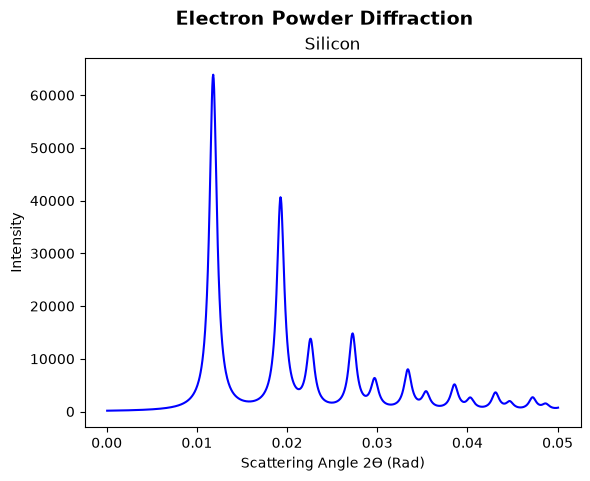

In [2]:
profile = silicon.generatePowder()
two_theta, intensity = profile

print('Profile:', profile.shape, f'from 2θ = {two_theta.min():.5f} to {two_theta.max():.3f} rad')
silicon.plotPowder(profile)

## Step 3: Index the peaks

The relativistic electron wavelength at 100 kV, and Silicon's reflections: the diamond structure
allows only $(hkl)$ all odd, or all even with $h + k + l$ a multiple of 4. For each spacing $d$,
the table gives the reflections, their multiplicity, and the scattering angle from Bragg's
law.

In [3]:
def wavelength(kv):
    """The relativistic electron wavelength in Å, at a high voltage in kV."""
    h, m0, e, c = 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19, 299792458.0
    E = kv * 1e3
    return h / math.sqrt(2 * m0 * e * E * (1 + e * E / (2 * m0 * c**2))) * 1e10


def allowed(h, k, l):
    """The diamond structure's reflection rule."""
    if h % 2 and k % 2 and l % 2:
        return True
    return h % 2 == 0 and k % 2 == 0 and l % 2 == 0 and (h + k + l) % 4 == 0


lam = wavelength(100)
a = silicon.cell.a
rings = {}            # h^2 + k^2 + l^2: the reflections on that ring
for hkl in itertools.product(range(-8, 9), repeat=3):
    if any(hkl) and allowed(*hkl):
        rings.setdefault(sum(i * i for i in hkl), []).append(hkl)

print(f'Wavelength at 100 kV: {lam:.5f} Å')
print()
print('  reflections     multiplicity   d (Å)    2θ (rad)')
peaks = []
for n in sorted(rings):
    d = a / math.sqrt(n)
    t = 2 * math.asin(lam / (2 * d))
    if t > two_theta.max():
        break
    names = sorted({tuple(sorted(map(abs, hkl), reverse=True)) for hkl in rings[n]})
    label = ', '.join(f'({h}{k}{l})' for h, k, l in names)
    peaks.append((t, label))
    print(f'  {label:16s} {len(rings[n]):6d}       {d:6.4f}   {t:.5f}')

Wavelength at 100 kV: 0.03701 Å

  reflections     multiplicity   d (Å)    2θ (rad)
  (111)                 8       3.1354   0.01181
  (220)                12       1.9200   0.01928
  (311)                24       1.6374   0.02261
  (400)                 6       1.3577   0.02726
  (331)                24       1.2459   0.02971
  (422)                24       1.1085   0.03339
  (333), (511)         32       1.0451   0.03542
  (440)                12       0.9600   0.03856
  (531)                48       0.9180   0.04033
  (620)                24       0.8587   0.04311
  (533)                24       0.8282   0.04470
  (444)                 8       0.7839   0.04723
  (551), (711)         48       0.7605   0.04868


(2 0 0) and (2 2 2) are missing: the diamond structure's two atoms per lattice point cancel
them. On the profile, each calculated angle sits on a peak:

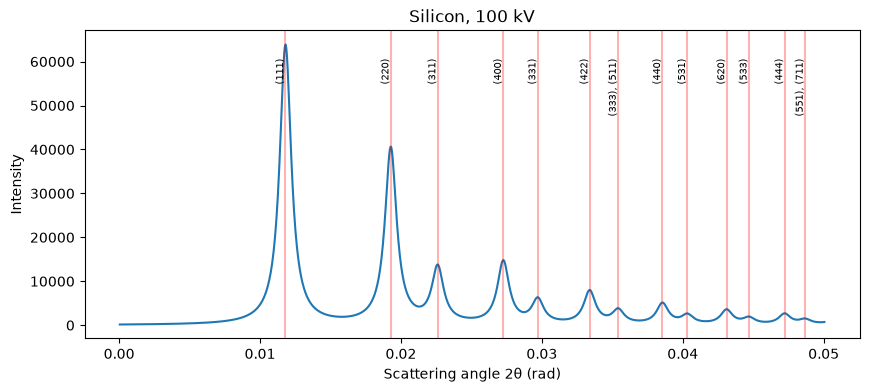

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(two_theta, intensity)
for t, label in peaks:
    ax.axvline(t, color='red', alpha=0.3)
    ax.text(t, intensity.max() * 0.95, label, rotation=90, fontsize=7, va='top', ha='right')
ax.set_xlabel('Scattering angle 2θ (rad)')
ax.set_ylabel('Intensity')
ax.set_title('Silicon, 100 kV')
plt.show()

## Step 4: Peak shape

Each peak has a **pseudo-Voigt** shape, a mix of a Lorentzian $L$ and a Gaussian $G$ of the same
full width at half maximum, `gamma`, in radians:

$$P = \eta\, L + (1 - \eta)\, G$$

`eta` = 1, the default, is purely Lorentzian, with long tails; `eta` = 0 is purely Gaussian. A
smaller `gamma` gives sharper peaks, as from larger grains or a finer instrument resolution.
Here is the (1 1 1) peak for a few values:

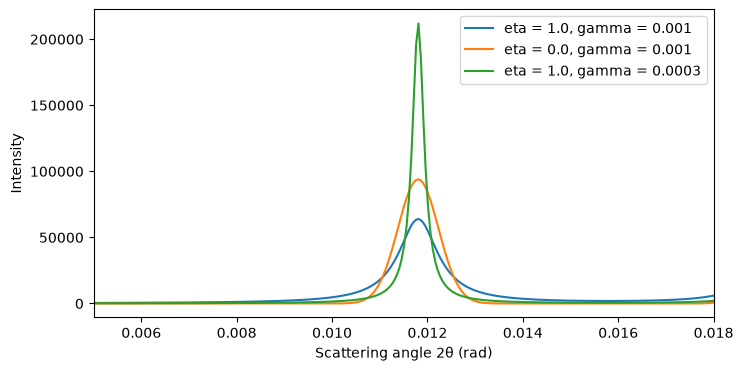

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
for eta, gamma in [(1.0, 0.001), (0.0, 0.001), (1.0, 0.0003)]:
    x, y = silicon.generatePowder(eta=eta, gamma=gamma)
    ax.plot(x, y, label=f'eta = {eta}, gamma = {gamma}')
ax.set_xlim(0.005, 0.018)
ax.set_xlabel('Scattering angle 2θ (rad)')
ax.set_ylabel('Intensity')
ax.legend()
plt.show()

## Step 5: High voltage

At a higher voltage the wavelength is shorter, and by Bragg's law every peak moves to a smaller
angle, in proportion to $\lambda$:

In [6]:
print('  kV    λ (Å)     (111) peak at 2θ   ratio to 100 kV')
for kv in (100, 200, 300):
    x, y = silicon.generatePowder(kv=kv, gamma=0.0002)
    peak = x[y.argmax()]
    if kv == 100:
        peak100 = peak
    print(f'  {kv}   {wavelength(kv):.5f}   {peak:.5f} rad        {peak / peak100:.3f}'
          f'   (λ ratio {wavelength(kv) / wavelength(100):.3f})')

  kV    λ (Å)     (111) peak at 2θ   ratio to 100 kV
  100   0.03701   0.01181 rad        1.000   (λ ratio 1.000)
  200   0.02508   0.00801 rad        0.678   (λ ratio 0.678)
  300   0.01969   0.00626 rad        0.530   (λ ratio 0.532)


## Step 6: Silicon and Diamond

The *powder.py* sample compares Silicon with Diamond, which has the same structure with a smaller
cell, 3.567 Å against 5.431 Å. Its peaks sit at larger angles, by the ratio of the cell
constants. `plot2Powder` shows the two profiles one above the other. The sample calculates
Diamond with absorption (`absp=1`).

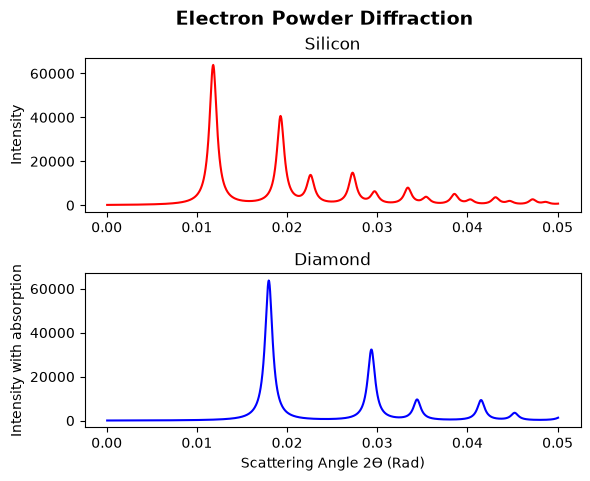

In [7]:
diamond = Crystal.from_builtin('Diamond')
diamond_profile = diamond.generatePowder(absp=1)

plot2Powder(profile, diamond_profile, titles=('Silicon', 'Diamond'),
            ylabels=('Intensity', 'Intensity with absorption'))

How much does absorption change a profile? pyEMAPS takes away the square of each
reflection's absorption structure factor from its intensity, $|F_{\mathbf g}|^2 -
|F'_{\mathbf g}|^2$. The absorption structure factors are small, so the change is too:

In [8]:
for crystal in (silicon, diamond):
    plain = crystal.generatePowder()[1]
    absorbing = crystal.generatePowder(absp=1)[1]
    change = np.abs(absorbing - plain).max() / plain.max()
    print(f'{crystal.name}: absorption changes the profile by at most {change:.4%} of its peak')

Silicon: absorption changes the profile by at most 0.0230% of its peak
Diamond: absorption changes the profile by at most 0.0015% of its peak


Far too little to see on the plot. Absorption matters much more for the intensities inside
CBED disks, in the [dynamic diffraction notebook](si_bloch.ipynb).

## Try it yourself

1. **Multiplicity.** (3 3 3) and (5 1 1) share a ring. How many reflections does it hold? Find
   it on the profile.
2. **Another crystal.** Calculate the profile of `Aluminium`, which is face-centred cubic with
   one atom per lattice point. Which reflections appear that Silicon doesn't have?
3. **Grain size.** Smaller grains give broader peaks. At what `gamma` do (3 3 1) and (4 2 2)
   merge into one peak?
4. **Camera length.** On a detector at camera length $L$, a ring has radius $R = L \tan 2\theta$.
   What are the radii of Silicon's first three rings at 100 kV and $L$ = 1 m?

## Next

- The kinematic diffraction notebook, [si_dif.ipynb](si_dif.ipynb): the pattern from one
  crystal, rather than many.
- The references for [`generatePowder`](https://emlab-solutions.github.io/pyemaps/api/crystals.html#pyemaps.crystals.Crystal.generatePowder)
  and [`plot2Powder`](https://emlab-solutions.github.io/pyemaps/api/display.html#pyemaps.display.plot2Powder).

## Further reading

J. M. Zuo and J. C. H. Spence, *Advanced Transmission Electron Microscopy* (Springer, New York,
2017), [doi:10.1007/978-1-4939-6607-3](https://doi.org/10.1007/978-1-4939-6607-3):

- chapter 3, *The Geometry of Electron Diffraction Patterns*, for Bragg's law and the scattering
  angles in Steps 3 and 5;
- chapter 4, *Kinematical Theory of Electron Diffraction*, for the structure factors behind the
  peak intensities.